In [1]:
import numpy as np
import math

## 填充函数

In [2]:
def MyPad(img, pad_size):
    if pad_size==0:
        return img
    return np.pad(img, pad_size, mode='constant', constant_values=0)

## 卷积函数

In [3]:
def MyConv2d(img, kernel, pad_size=1, stride=1):
    img = MyPad(img, pad_size)
    img_height, img_width = img.shape
    kernel_height, kernel_width = kernel.shape

    # 计算输出图尺寸
    out_height = (img_height - kernel_height) // stride + 1
    out_width = (img_width - kernel_width) // stride + 1

    out = np.zeros((out_height, out_width))

    for i in range(out_height):
        for j in range(out_width):
            start_i = i*stride
            start_j = j*stride
            arr = img[start_i:start_i+kernel_height, start_j:start_j+kernel_width]
            out[i][j] = np.sum(arr*kernel)
    return out

## 现在来调用我的卷积函数看看，图片还是用那张

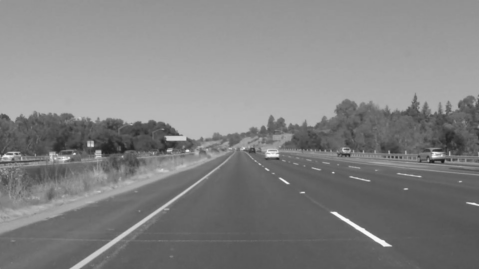

In [4]:
from PIL import Image
kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1],
]) / 16 # 核和为1的高斯卷积核
img = Image.open("./attachment/outer1.png").convert('L') #二维卷积核只能卷单通道的

arr = np.array(img).astype(np.float32)
result = Image.fromarray(np.clip(MyConv2d(arr, kernel, 0, 2), 0, 255).astype(np.uint8))
result

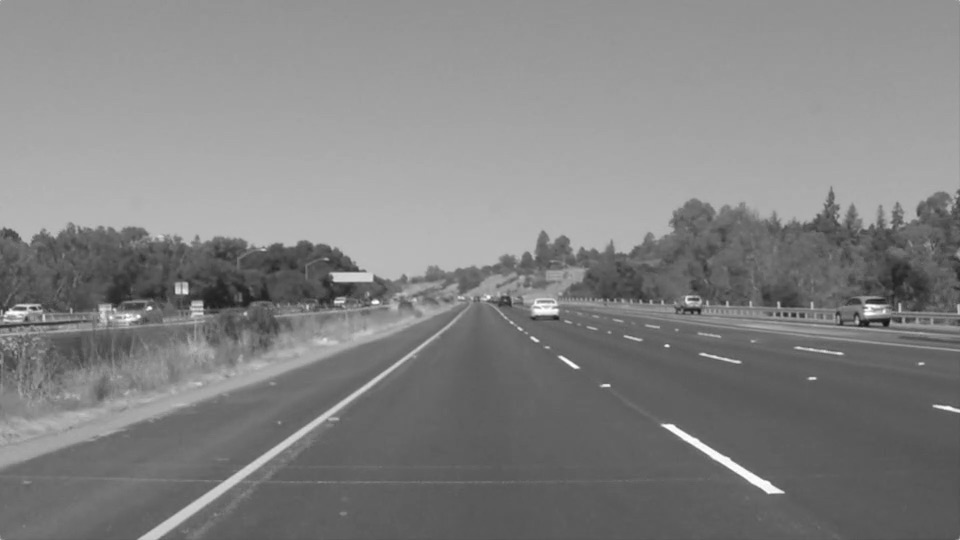

In [5]:
img

## 任务第五点，各类卷积核定义
高斯函数的公式:$G(x, y) = \exp\left(-\frac{x^2 + y^2}{2\sigma^2}\right)
$

In [6]:
# 均值模糊
mean_kernel = np.ones((3, 3), dtype=np.float32) / 9.0

# 高斯模糊
size = 5
ax = np.arange(5) - size//2
xx, yy = np.meshgrid(ax, ax)
sigma = 1.0
gauss_kernel = np.exp(-(xx**2 + yy**2)/(2*sigma**2))
gauss_kernel = (kernel / kernel.sum()).astype(np.float32)

# 锐化
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

# 边缘检测
gx_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])
gy_kernel = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

## 调用各类核，得到输出结果

### 均值模糊

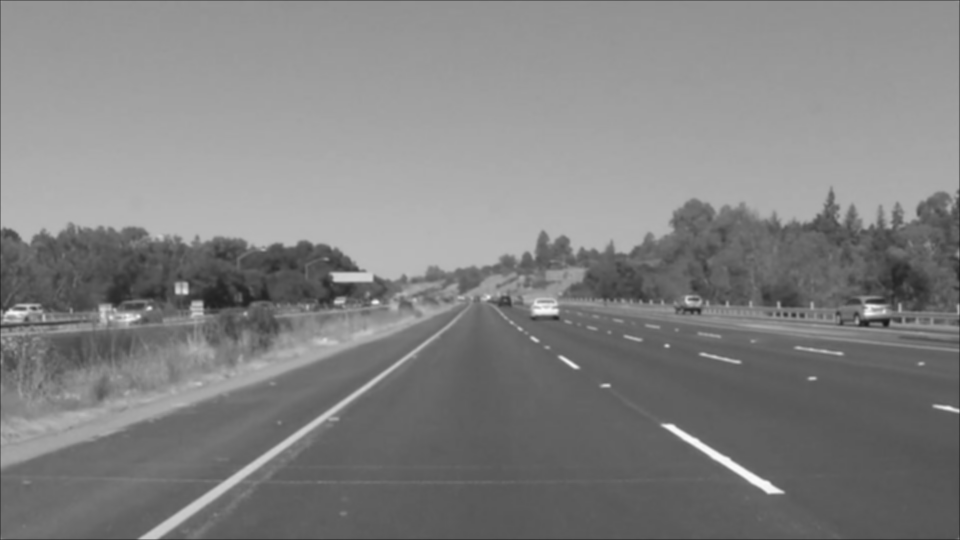

In [7]:
result1 = Image.fromarray(np.clip(MyConv2d(arr, mean_kernel, 1, 1), 0, 255).astype(np.uint8))
result1

### 高斯模糊

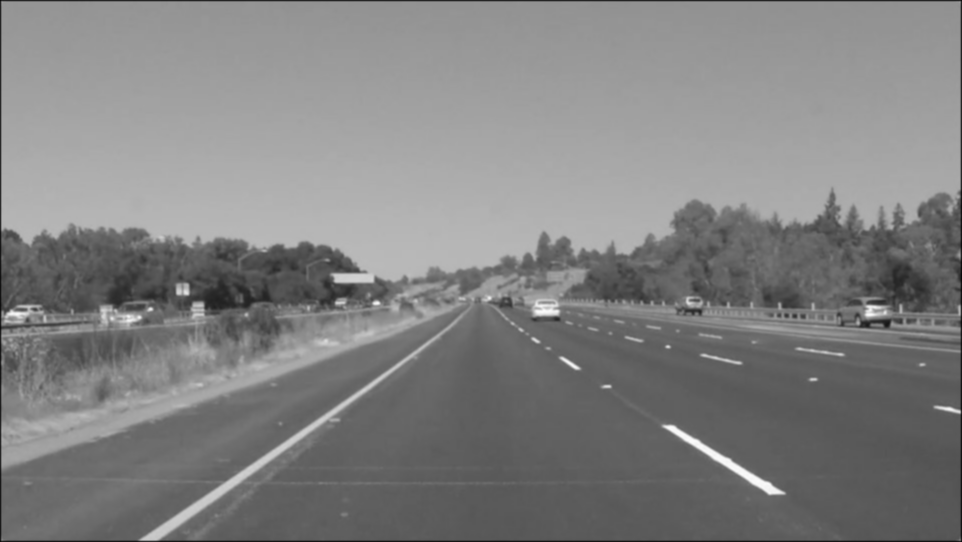

In [8]:
result2 = Image.fromarray(np.clip(MyConv2d(arr, gauss_kernel, 2, 1), 0, 255).astype(np.uint8))
result2

### 锐化

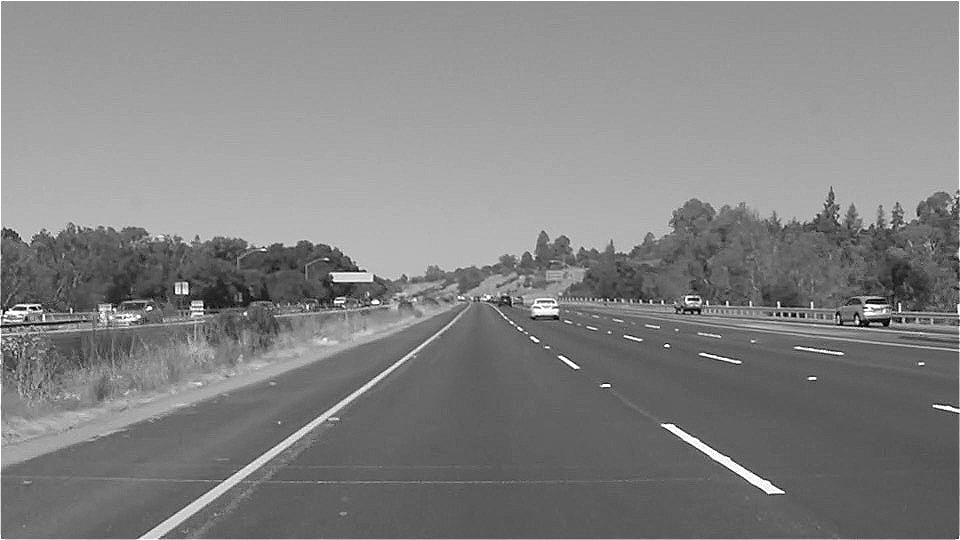

In [9]:
result3 = Image.fromarray(np.clip(MyConv2d(arr, sharpen_kernel, 1, 1), 0, 255).astype(np.uint8))
result3

### 边缘检测

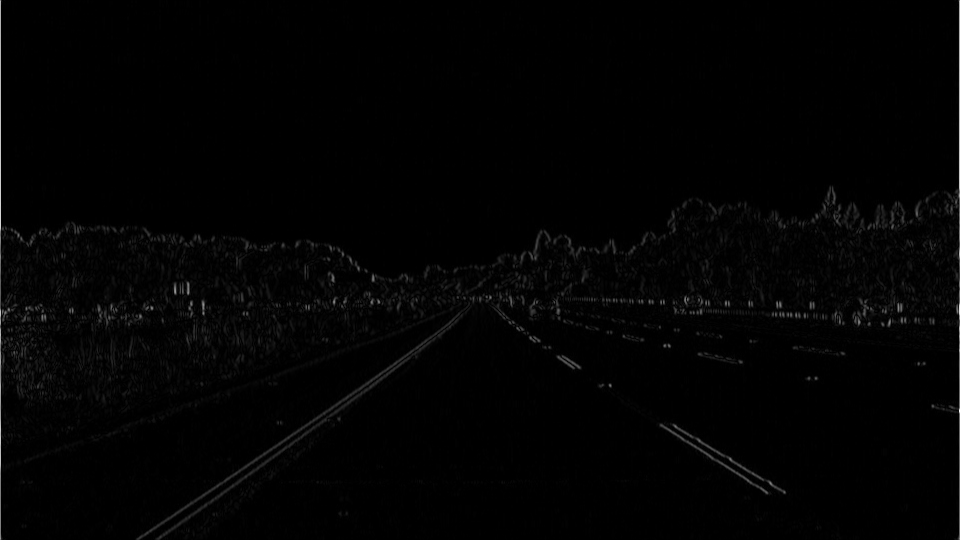

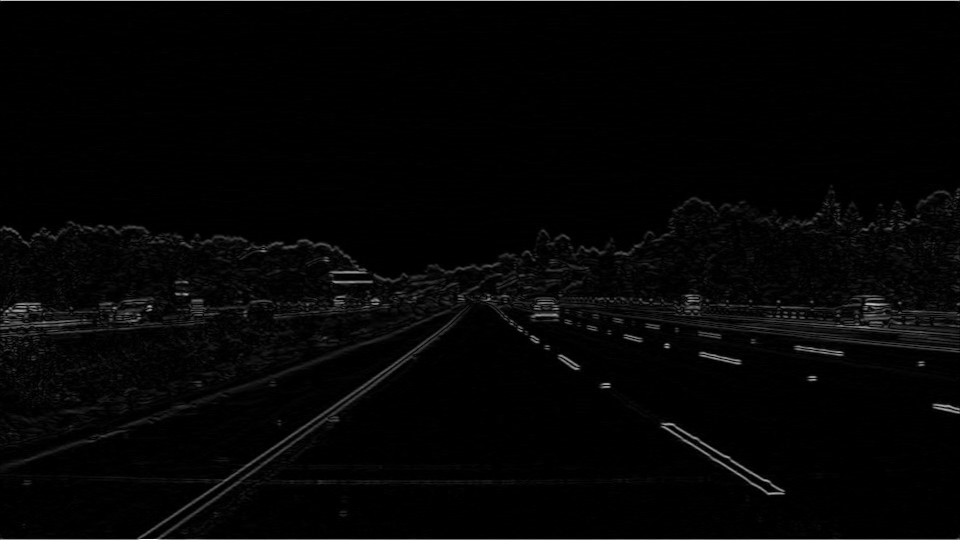

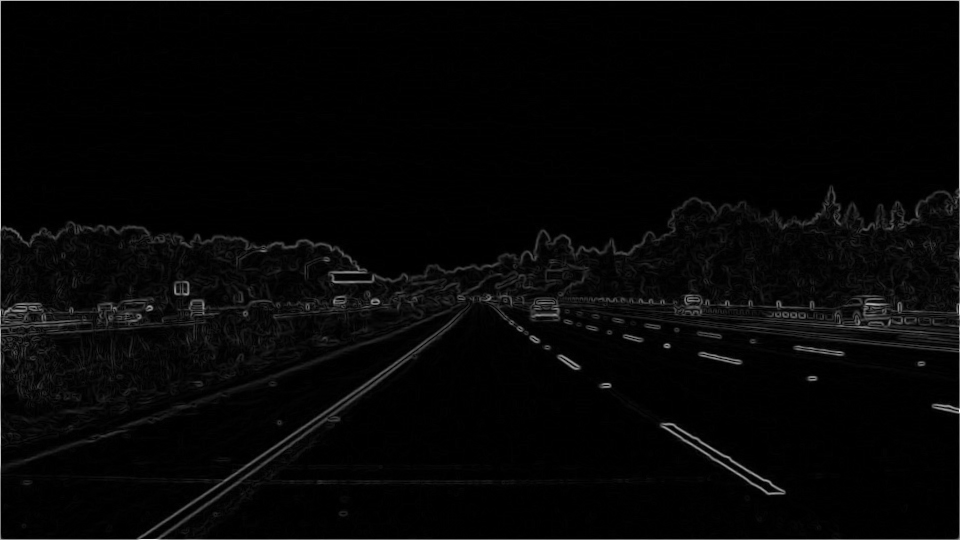

In [13]:
def to_uint8(x, Normalize=False):
    x = x.astype(np.float32)
    if Normalize:
        x_min, x_max = x.min(), x.max()
        if x_max - x_min < 1e-8:
            x = np.zeros_like(x)
        else:
            x = (x - x_min) / (x_max - x_min) * 255
    else:
        x = np.clip(x, 0, 255)
    return x.astype(np.uint8)
    
gx = MyConv2d(arr, gx_kernel, 1, 1)
gy = MyConv2d(arr, gy_kernel, 1, 1)

gx_img = Image.fromarray(to_uint8(np.abs(gx), Normalize=True))
gy_img = Image.fromarray(to_uint8(np.abs(gy), Normalize=True))
edge = np.sqrt(gx**2 + gy**2)
edge_img = Image.fromarray(to_uint8(np.abs(edge), Normalize=True))

display(gx_img)
display(gy_img)
display(edge_img)

### 简单的对比

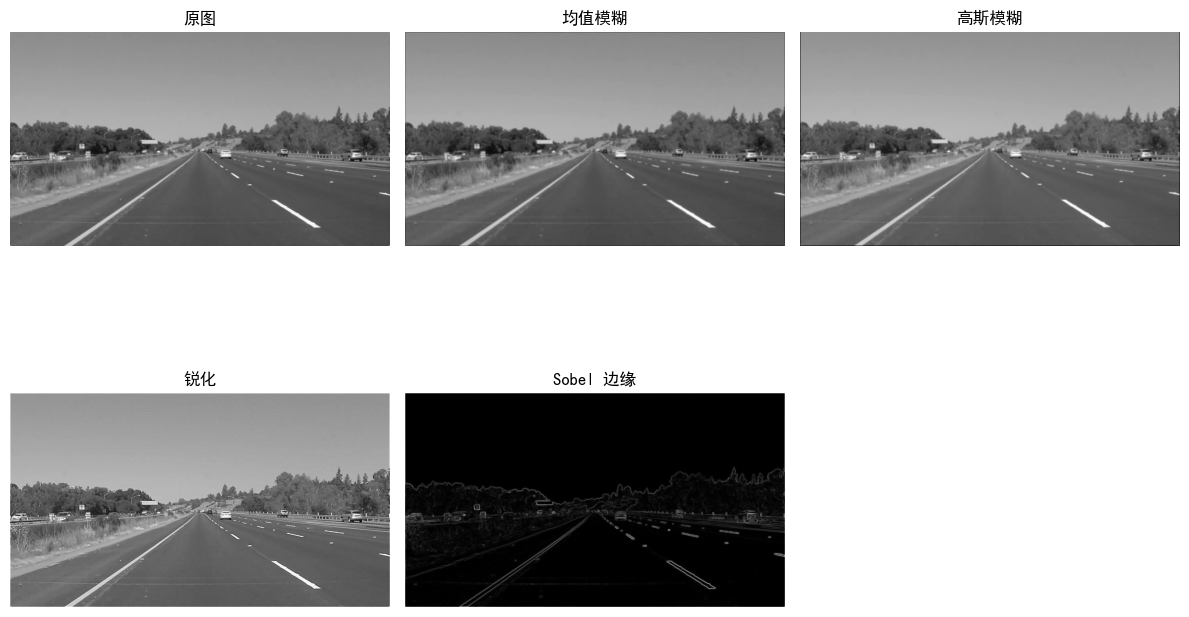

In [20]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False
imgs = [img, result1, result2, result3, edge_img]
titles = ["原图", "均值模糊", "高斯模糊", "锐化", "Sobel 边缘"]

plt.figure(figsize=(12, 8))

for i, (im, title) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()